# Notebook 02 - Q3: Phân tích Chuyên sâu Câu hỏi Q3 (Tỷ suất đồng xuất hiện ROR Hoạt chất x Triệu chứng)
**Đề tài:** Phân tích Sự cố Bất lợi Thuốc Thú y (OpenFDA Animal & Veterinary Adverse Events) giai đoạn 2025 và Đối chiếu Xu hướng 2026 (Q1)

**Môn học:** CSC17104 – Lập trình cho Khoa học Dữ liệu  
**Nhóm thực hiện:** Global Ban  
**Thành viên phụ trách:** Huỳnh Tuấn Kiệt (M3 — MSSV: `24120356`)  
**Phản biện chéo:** Trần Ngô Uyên Nhi (M2)  
**Liên kết Master Hub:** [Notebook 02: Master Hub (Mục 3.3 Question Formulation & D1–D6)](02_analysis.ipynb)

In [1]:
import sys
import re
from pathlib import Path
import numpy as np
import pandas as pd
import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.data_loader import load_processed
from src.preprocessing import (
    KEY,
    load_clean_tables,
    run_core_preprocessing,
    save_clean_tables,
    log_row_count_change,
)
from src.visualization import set_project_plot_style

set_project_plot_style()

In [2]:
# Tải 4 bảng dữ liệu sạch chuẩn hóa từ pipeline tiền xử lý lõi Task T14 (src/preprocessing.py)
RAW_PROC_DIR = PROJECT_ROOT / "data" / "processed"
CLEAN_PROC_DIR = RAW_PROC_DIR / "clean"

raw_tables = load_processed(RAW_PROC_DIR)
if not (CLEAN_PROC_DIR / "reports.csv").exists():
    clean_tables, _ = run_core_preprocessing(raw_tables, verbose=True)
    save_clean_tables(clean_tables, CLEAN_PROC_DIR)
else:
    clean_tables = load_clean_tables(CLEAN_PROC_DIR)

reports = clean_tables["reports"]
drugs = clean_tables["drugs"]
reactions = clean_tables["reactions"]
outcomes = clean_tables["outcomes"]

print("=== ĐỐI CHIẾU QUY MÔ DỮ LIỆU THÔ (data/processed) -> SẠCH LÕI T14 (data/processed/clean) ===")
for name in ("reports", "drugs", "reactions", "outcomes"):
    log_row_count_change(
        f"T14_core_{name}",
        len(raw_tables[name]),
        len(clean_tables[name]),
        "Làm sạch lõi T14 (loại ca Human, chuẩn hóa thiếu ẩn/ngày/sinh trắc học, khử trùng lặp reactions)",
    )
print(
    f"\n[Clean Data Ready] Reports: {reports.shape}, Drugs: {drugs.shape}, "
    f"Reactions: {reactions.shape}, Outcomes: {outcomes.shape}"
)

=== ĐỐI CHIẾU QUY MÔ DỮ LIỆU THÔ (data/processed) -> SẠCH LÕI T14 (data/processed/clean) ===
[T14_core_reports] Rows: 94,412 -> 93,812 (Change: -600 | -0.64%) | Reason: Làm sạch lõi T14 (loại ca Human, chuẩn hóa thiếu ẩn/ngày/sinh trắc học, khử trùng lặp reactions)
[T14_core_drugs] Rows: 174,123 -> 173,221 (Change: -902 | -0.52%) | Reason: Làm sạch lõi T14 (loại ca Human, chuẩn hóa thiếu ẩn/ngày/sinh trắc học, khử trùng lặp reactions)
[T14_core_reactions] Rows: 270,244 -> 267,848 (Change: -2,396 | -0.89%) | Reason: Làm sạch lõi T14 (loại ca Human, chuẩn hóa thiếu ẩn/ngày/sinh trắc học, khử trùng lặp reactions)
[T14_core_outcomes] Rows: 85,143 -> 84,543 (Change: -600 | -0.70%) | Reason: Làm sạch lõi T14 (loại ca Human, chuẩn hóa thiếu ẩn/ngày/sinh trắc học, khử trùng lặp reactions)

[Clean Data Ready] Reports: (93812, 53), Drugs: (173221, 31), Reactions: (267848, 8), Outcomes: (84543, 6)


---
## Câu hỏi Q3: Tỷ suất Đồng xuất hiện (ROR) Hoạt chất x Triệu chứng (Safety Issue vs Lack of Efficacy)

### Phát biểu câu hỏi và Động lực
- **Phát biểu câu hỏi:**  
  > **"Các hoạt chất (`active_ingredients`) và đường dùng (`route`) nào có tỷ suất đồng xuất hiện (Reporting Odds Ratio) đặc trưng nhất với từng phản ứng cụ thể, và pattern này khác biệt ra sao giữa nhóm Safety Issue và Lack Of Expected Effectiveness trong năm 2025?"**
- **Người quan tâm & Quyết định hỗ trợ (Target Users & Decisions):**
  - **Chuyên gia Cảnh giác dược (FDA CVM) & Bộ phận R&D Dược phẩm Thú y:** Cần tách biệt rõ tín hiệu **độc tính sinh học thực sự (*Safety Issue*)** (như nhiễm toan ceton do thuốc ức chế SGLT2, mất điều hòa vận động/uống nhiều do kháng thể đơn dòng kháng NGF, tăng men gan hay nôn mửa cấp tính) khỏi các báo cáo **giảm hiệu lực / kháng thuốc (*Lack Of Expected Effectiveness — LOEE*)** (như thất bại dự phòng giun tim *Dirofilaria immitis*, kháng thuốc diệt bọ chét/ve hoặc vắc-xin Lyme *Borrelia*). Nếu gộp chung hai nhóm này khi tính ROR trên toàn bộ cơ sở dữ liệu, các thuốc trị ký sinh trùng có hàng chục nghìn báo cáo LOEE sẽ làm loãng mẫu số và che khuất các tín hiệu độc tính nguy hiểm của thuốc điều trị nội khoa.
  - **Bác sĩ thú y lâm sàng:** Hiểu rõ rủi ro đặc thù theo từng đường dùng thuốc (`Oral`, `Topical`, `Subcutaneous`, `Intravenous`, `Auricular`, `Nasal`) để tư vấn theo dõi triệu chứng mục tiêu sau cấp thuốc.
- **Tiêu chí độ sâu áp dụng (Mục 3.3 — bao phủ 4 tiêu chí D1, D2, D4, D5):**
  - **`D1` (Combining data):** Kết nối 3 bảng quan hệ `reports`, `drugs`, `reactions` qua khóa `unique_aer_id_number`; kiểm tra toàn vẹn khóa nối và **chống bùng nổ tổ hợp (Cartesian explosion)** bằng cách chuẩn hóa & khử trùng lặp về cấp báo cáo `(unique_aer_id_number, ingredient)` và `(unique_aer_id_number, veddra_term_name)` trước khi dựng bảng liên hợp $2 \times 2$.
  - **`D2` (Reshaping & time):** Xoay trục (`pivot_table` / `melt`) ma trận $\log_2(\text{ROR})$ giữa **Hoạt chất $\times$ Phản ứng** và **Đường dùng $\times$ Phản ứng** đối sánh hai nhóm `Safety Issue` vs. `Lack Of Expected Effectiveness`; đồng thời phân tích chuỗi thời gian theo từng quý (`2025Q1` $\rightarrow$ `2025Q4` và đối chiếu `2026Q1`) để kiểm chứng tính bền vững của các tín hiệu cảnh giác dược hàng đầu.
  - **`D4` (Controlling for a confounder):** Kiểm soát biến nhiễu **Loài vật nuôi (`species`: Chó `Dog` vs. Mèo `Cat`)** thông qua phân tầng (Stratified ROR) và ước lượng **Tỷ số chênh đồng xuất hiện hiệu chỉnh Cochran–Mantel–Haenszel ($\text{ROR}_{\text{MH}}$)** nhằm loại trừ hiện tượng nhiễu giả do thuốc chỉ định chuyên biệt theo loài.
  - **`D5` (Quantifying uncertainty):** Ước lượng **Reporting Odds Ratio (ROR)**, **Proportional Reporting Ratio (PRR)**, khoảng tin cậy **95% CI** theo phương pháp Woolf/Haldane–Anscombe, kiểm định $\chi^2$ hiệu chỉnh Yates và kiểm soát tỷ lệ phát hiện sai đa kiểm định bằng **Benjamini–Hochberg FDR ($q$-value)**.

### 1. Tiền xử lý cho Q3

Tuân thủ **Mục 3.4 (Data Analysis — Preprocessing)**, quy trình tiền xử lý chuyên biệt cho Q3 kế thừa trực tiếp 4 bảng sạch từ **Task T14 (`data/processed/clean/`)** và thực hiện 5 bước biến đổi có ghi vết số dòng (`log_row_count_change`):

1. **Bước 1.1 — Lọc khung thời gian phân tích năm 2025 (`2025q1`–`2025q4`):**
   - Giữ lại các báo cáo thú y trong 4 quý năm 2025 để phân tích cấu trúc đồng xuất hiện cả năm; đồng thời trích riêng tập `2026q1` để đối chiếu độ ổn định tín hiệu theo thời gian ở tiêu chí **D2**.
2. **Bước 1.2 — Phân nhóm bản chất biến cố (`event_category`) từ `type_of_information`:**
   - Ánh xạ các nhãn chi tiết về 4 nhóm chuẩn: **`Safety Issue`** (bao gồm cả *Safety Issue (Clinical Studies)*), **`Lack Of Expected Effectiveness`** (bao gồm cả *LOEE (Clinical Studies)*), **`Both Safety & LOEE`**, và **`Product/Manufacturing Defect`**.
   - Loại bỏ các báo cáo chỉ phản ánh lỗi bao bì/sản xuất mà không có biến cố lâm sàng (`Product/Manufacturing Defect` và `Other/Unknown`) khỏi tập phân tích dược lý lâm sàng.
3. **Bước 1.3 — Đồng bộ bảng `drugs` & Lọc bỏ dòng khuyết hoạt chất hiệu dụng (`active_ingredients_clean`):**
   - Kết nối bảng `drugs` với tập báo cáo lâm sàng năm 2025 và loại bỏ các dòng thuốc có `active_ingredients_clean` là `NaN` (đã được Task T14 gom từ `NaN` gốc và các chuỗi thiếu ẩn như `'Noinformationsupplied'`, `'Unknown'`, `'Unknown Medication'`, `'*(Unknown)'`).
4. **Bước 1.4 — Chuẩn hóa danh pháp Hoạt chất đơn lẻ (Canonicalization) & Khử trùng lặp cấp báo cáo:**
   - Khắc phục triệt để vấn đề chất lượng dữ liệu phát hiện ở **EDA Mục 2.3.2**: tách các chế phẩm đa hoạt chất nối bằng `';'`, `','` hoặc `'/'` (ví dụ `Pyrantel Pamoate;Sarolaner`, `Lotilaner,Moxidectin,Praziquantel,Pyrantel Pamoate`, `Afoxolaner 75Mg / Moxidectin 360Mcg / Pyrantel 150Mg Chewable Tablet`); loại bỏ hậu tố gốc muối (`pamoate`, `maleate`, `citrate`, `monohydrate`, `oxime`...) và thông số hàm lượng/dạng bào chế (`13.64% 12-week chew`, `spot-on solution`...); ánh xạ viết tắt (`Pzq` $\rightarrow$ `Praziquantel`, `Anti-IL31 mAb` $\rightarrow$ `Lokivetmab`).
   - Khử trùng lặp theo cặp `(unique_aer_id_number, ingredient)` và `(unique_aer_id_number, route)` để mỗi báo cáo chỉ tính tối đa 1 lần phơi nhiễm cho mỗi hoạt chất/đường dùng.
5. **Bước 1.5 — Kết nối với bảng `reactions` (Tiêu chí D1) & Kiểm định chống bùng nổ tổ hợp:**
   - Bảng `reactions` từ Task T14 đã được khử 570 dòng trùng hoàn toàn và 8 cặp trùng `(unique_aer_id_number, veddra_term_code)`. Nhóm tiếp tục khử trùng theo `(unique_aer_id_number, veddra_term_name)` và thực hiện phép nối có kiểm soát ở cấp báo cáo.

In [3]:
# ===== 1. Thực thi Tiền xử lý chuyên biệt cho Q3 kèm log_row_count_change =====
QUARTERS_2025 = ("2025q1", "2025q2", "2025q3", "2025q4")

# Bước 1.1: Lọc báo cáo năm 2025 (4 quý)
rep_2025_all = reports[reports["quarter"].isin(QUARTERS_2025)].copy()
log_row_count_change(
    "Q3_step1_filter_2025_reports",
    len(reports),
    len(rep_2025_all),
    "Lọc báo cáo thú y thuộc 4 quý năm 2025 (2025q1-2025q4)",
)

# Bước 1.2: Phân loại bản chất biến cố từ type_of_information
def classify_event_category(val: str) -> str:
    s = str(val).strip().lower()
    has_safety = "safety" in s
    has_loee = ("lack of expected effectiveness" in s) or ("loee" in s)
    if has_safety and not has_loee and "defect" not in s:
        return "Safety Issue"
    if has_loee and not has_safety and "defect" not in s:
        return "Lack Of Expected Effectiveness"
    if has_safety and has_loee and "defect" not in s:
        return "Both Safety & LOEE"
    if "defect" in s:
        return "Product/Manufacturing Defect"
    return "Other/Unknown"

rep_2025_all["event_category"] = rep_2025_all["type_of_information"].map(classify_event_category)

CLINICAL_CATEGORIES = ("Safety Issue", "Lack Of Expected Effectiveness", "Both Safety & LOEE")
rep_q3 = rep_2025_all[rep_2025_all["event_category"].isin(CLINICAL_CATEGORIES)].copy()
log_row_count_change(
    "Q3_step2_exclude_product_defects",
    len(rep_2025_all),
    len(rep_q3),
    "Loại bỏ báo cáo lỗi sản xuất/bao bì (Product Defect) và Other/Unknown không phản ánh tương tác dược lý",
)

# Bước 1.3: Đồng bộ bảng drugs với tập báo cáo lâm sàng 2025 & lọc dòng có hoạt chất hợp lệ
drg_2025 = drugs[drugs[KEY].isin(rep_q3[KEY])].copy()
log_row_count_change(
    "Q3_step3a_sync_drugs_2025_clinical",
    len(drugs),
    len(drg_2025),
    "Giữ các lượt thuốc thuộc tập báo cáo lâm sàng năm 2025",
)

drg_q3_valid = drg_2025.dropna(subset=["active_ingredients_clean"]).copy()
log_row_count_change(
    "Q3_step3b_drop_missing_active_ing",
    len(drg_2025),
    len(drg_q3_valid),
    "Loại bỏ dòng thuốc khuyết active_ingredients_clean (NaN và thiếu ẩn đã chuẩn hóa ở T14)",
)

# Bước 1.4: Tách đa hoạt chất & chuẩn hóa danh pháp hoạt chất gốc (Canonicalization)
INGREDIENT_STRIP_RE = re.compile(
    r"\b(?:as\s+pamoate\s+salt|pamoate|maleate|citrate|hydrochloride|hcl|sodium|potassium|"
    r"calcium|acetate|sulfate|sulphate|phosphate|tartrate|mesylate|besylate|fumarate|"
    r"succinate|benzoate|lactate|gluconate|valerate|propionate|palmitate|stearate|"
    r"monohydrate|dihydrate|trihydrate|anhydrous|proline|oxime|"
    r"chewable|tablets?|chews?|spot[\-\s]*on|solutions?|powders?|for|inj(?:ectable|ection)?|"
    r"susp(?:ension)?|oral|topical|drops?|capsules?|gels?|creams?|ointments?|sprays?|"
    r"lot\s*#?\s*\w+|mcs)\b"
    r"|\b\d+(?:\.\d+)?\s*(?:%|(?:mg|mcg|ug|g|kg|ml|l|iu|[\-\s]*week|[\-\s]*month|[\-\s]*day)\b)"
    r"|\(\s*.*?\s*\)",
    flags=re.IGNORECASE,
)
INGREDIENT_ALIASES = {
    "Pzq": "Praziquantel",
    "Anti-Il31 Mab": "Lokivetmab",
    "Recombinant E Coli Bl21": "Recombinant E. Coli (Bl21/Ecl19)",
    "Recombinant E Coli Ecl19": "Recombinant E. Coli (Bl21/Ecl19)",
}

def canonicalize_ingredient(token: str) -> str:
    s = str(token).replace("\xa0", " ")
    s = INGREDIENT_STRIP_RE.sub(" ", s)
    s = re.sub(r"[^a-zA-Z0-9\-\s]", " ", s)
    s = re.sub(r"\s+", " ", s).strip().title()
    s = re.sub(r"^[\-\s]+|[\-\s]+$", "", s)
    return INGREDIENT_ALIASES.get(s, s)

drg_exploded = (
    drg_q3_valid[[KEY, "route", "active_ingredients_clean"]]
    .assign(raw_token=lambda d: d["active_ingredients_clean"].str.replace("\xa0", " ").str.split(r"[;,/]"))
    .explode("raw_token")
)
drg_exploded["ingredient"] = drg_exploded["raw_token"].map(canonicalize_ingredient)
drg_exploded = drg_exploded[drg_exploded["ingredient"].str.len() > 2].copy()
log_row_count_change(
    "Q3_step4a_explode_combination_drugs",
    len(drg_q3_valid),
    len(drg_exploded),
    "Tách thuốc đa thành phần (;,/) thành từng hoạt chất đơn lẻ đã chuẩn hóa gốc muối/hàm lượng",
)

rep_ing_q3 = drg_exploded[[KEY, "ingredient"]].drop_duplicates().copy()
log_row_count_change(
    "Q3_step4b_dedup_report_ingredient",
    len(drg_exploded),
    len(rep_ing_q3),
    "Khử trùng lặp cấp (unique_aer_id_number, ingredient) để chống bùng nổ tổ hợp khi nối với reactions",
)

# Chuẩn bị bảng đường dùng cấp báo cáo (loại 'Unknown' khi tính ROR đường dùng)
rep_route_q3 = (
    drg_2025.loc[drg_2025["route"].ne("Unknown"), [KEY, "route"]]
    .drop_duplicates()
    .copy()
)
log_row_count_change(
    "Q3_step4c_dedup_report_known_route",
    len(drg_2025),
    len(rep_route_q3),
    "Lọc đường dùng đã xác định (route != 'Unknown') và khử trùng lặp cấp (unique_aer_id_number, route)",
)

# Bước 1.5: Đồng bộ bảng reactions với tập báo cáo lâm sàng 2025 (D1)
rea_2025 = reactions[reactions[KEY].isin(rep_q3[KEY])].copy()
log_row_count_change(
    "Q3_step5a_sync_reactions_2025_clinical",
    len(reactions),
    len(rea_2025),
    "Đồng bộ bảng reactions với tập báo cáo lâm sàng năm 2025",
)

rep_rea_q3 = rea_2025[[KEY, "veddra_term_name"]].dropna().drop_duplicates().copy()
log_row_count_change(
    "Q3_step5b_dedup_report_veddra_term",
    len(rea_2025),
    len(rep_rea_q3),
    "Khử trùng lặp cấp (unique_aer_id_number, veddra_term_name) đảm bảo mỗi triệu chứng tính 1 lần/báo cáo",
)

# Kiểm định toàn vẹn khóa nối D1
n_rep_clin = rep_q3[KEY].nunique()
n_rep_with_ing = rep_ing_q3[KEY].nunique()
n_rep_with_rea = rep_rea_q3[KEY].nunique()
n_rep_joint = len(set(rep_ing_q3[KEY]) & set(rep_rea_q3[KEY]))
print(
    f"\n[Kiểm định kết nối D1] Tổng báo cáo lâm sàng 2025: {n_rep_clin:,} | "
    f"Có hoạt chất chuẩn hóa: {n_rep_with_ing:,} ({n_rep_with_ing/n_rep_clin*100:.2f}%) | "
    f"Có triệu chứng VeDDRA: {n_rep_with_rea:,} ({n_rep_with_rea/n_rep_clin*100:.2f}%) | "
    f"Khớp đồng thời cả 2 bảng: {n_rep_joint:,} ({n_rep_joint/n_rep_clin*100:.2f}%)"
)

cat_summary = (
    rep_2025_all.groupby("event_category")[KEY]
    .nunique()
    .rename("Số báo cáo (2025)")
    .to_frame()
    .assign(**{"Tỷ trọng (%)": lambda d: d["Số báo cáo (2025)"] / len(rep_2025_all) * 100})
    .sort_values("Số báo cáo (2025)", ascending=False)
)
display(cat_summary.style.format({"Số báo cáo (2025)": "{:,}", "Tỷ trọng (%)": "{:.2f}%"}))

[Q3_step1_filter_2025_reports] Rows: 93,812 -> 76,630 (Change: -17,182 | -18.32%) | Reason: Lọc báo cáo thú y thuộc 4 quý năm 2025 (2025q1-2025q4)
[Q3_step2_exclude_product_defects] Rows: 76,630 -> 67,831 (Change: -8,799 | -11.48%) | Reason: Loại bỏ báo cáo lỗi sản xuất/bao bì (Product Defect) và Other/Unknown không phản ánh tương tác dược lý


[Q3_step3a_sync_drugs_2025_clinical] Rows: 173,221 -> 132,235 (Change: -40,986 | -23.66%) | Reason: Giữ các lượt thuốc thuộc tập báo cáo lâm sàng năm 2025
[Q3_step3b_drop_missing_active_ing] Rows: 132,235 -> 125,451 (Change: -6,784 | -5.13%) | Reason: Loại bỏ dòng thuốc khuyết active_ingredients_clean (NaN và thiếu ẩn đã chuẩn hóa ở T14)


[Q3_step4a_explode_combination_drugs] Rows: 125,451 -> 177,904 (Change: +52,453 | +41.81%) | Reason: Tách thuốc đa thành phần (;,/) thành từng hoạt chất đơn lẻ đã chuẩn hóa gốc muối/hàm lượng
[Q3_step4b_dedup_report_ingredient] Rows: 177,904 -> 170,730 (Change: -7,174 | -4.03%) | Reason: Khử trùng lặp cấp (unique_aer_id_number, ingredient) để chống bùng nổ tổ hợp khi nối với reactions
[Q3_step4c_dedup_report_known_route] Rows: 132,235 -> 76,417 (Change: -55,818 | -42.21%) | Reason: Lọc đường dùng đã xác định (route != 'Unknown') và khử trùng lặp cấp (unique_aer_id_number, route)


[Q3_step5a_sync_reactions_2025_clinical] Rows: 267,848 -> 202,433 (Change: -65,415 | -24.42%) | Reason: Đồng bộ bảng reactions với tập báo cáo lâm sàng năm 2025
[Q3_step5b_dedup_report_veddra_term] Rows: 202,433 -> 202,433 (Change: +0 | +0.00%) | Reason: Khử trùng lặp cấp (unique_aer_id_number, veddra_term_name) đảm bảo mỗi triệu chứng tính 1 lần/báo cáo



[Kiểm định kết nối D1] Tổng báo cáo lâm sàng 2025: 67,831 | Có hoạt chất chuẩn hóa: 67,365 (99.31%) | Có triệu chứng VeDDRA: 67,831 (100.00%) | Khớp đồng thời cả 2 bảng: 67,365 (99.31%)


,Số báo cáo (2025),Tỷ trọng (%)
event_category,,
Safety Issue,"38,127",49.75%
Lack Of Expected Effectiveness,"23,811",31.07%
Product/Manufacturing Defect,"8,775",11.45%
Both Safety & LOEE,"5,893",7.69%
Other/Unknown,24,0.03%


### 2. Phương pháp phân tích

1. **Thiết kế Bảng liên hợp $2 \times 2$ cấp Báo cáo & Công thức ROR / PRR (Tiêu chí D1 & D5):**
   - Trong mỗi quần thể báo cáo khảo sát $\mathcal{C}$ (với quy mô $N = |\mathcal{C}|$ báo cáo duy nhất có đủ cả thông tin phơi nhiễm và triệu chứng), xét một yếu tố phơi nhiễm $E$ (hoạt chất hoặc đường dùng) và một phản ứng VeDDRA $R$:
     - $a$: Số báo cáo có mặt đồng thời cả $E$ và $R$.
     - $b$: Số báo cáo có $E$ nhưng không có $R$ ($n_E - a$).
     - $c$: Số báo cáo không có $E$ nhưng có $R$ ($n_R - a$).
     - $d$: Số báo cáo không có cả $E$ lẫn $R$ ($N - a - b - c$).
   - **Tỷ số chênh báo cáo (Reporting Odds Ratio — ROR)** và **Khoảng tin cậy 95% (Woolf Logit CI)**:
     $$\text{ROR} = \frac{a \cdot d}{b \cdot c}, \qquad \text{SE}(\ln \text{ROR}) = \sqrt{\frac{1}{a} + \frac{1}{b} + \frac{1}{c} + \frac{1}{d}}, \qquad \text{CI}_{95\%} = \exp\!\left(\ln \text{ROR} \pm 1.96 \cdot \text{SE}(\ln \text{ROR})\right)$$
     *(Áp dụng hiệu chỉnh liên tục Haldane–Anscombe $+0.5$ vào cả 4 ô khi có bất kỳ ô nào bằng $0$).*
   - **Kiểm soát đa kiểm định (Multiple Testing Correction):** Giá trị $p$-value từ kiểm định $\chi^2$ hiệu chỉnh Yates được điều chỉnh bằng thủ tục **Benjamini–Hochberg False Discovery Rate ($q_{\text{FDR}}$)**. Một cặp $(E, R)$ được xác nhận là **tín hiệu cảnh giác dược có ý nghĩa thống kê** khi thỏa mãn đồng thời: $a \ge 15$, $\text{ROR} \ge 2.0$, $\text{CI}_{95\%,\text{lower}} > 1.0$, và $q_{\text{FDR}} < 0.01$.
2. **Đối sánh cấu trúc giữa `Safety Issue` và `Lack Of Expected Effectiveness` (Tiêu chí D2):**
   - Thực hiện phân tích ROR độc lập trong từng phân nhóm **`Safety Issue`** ($N_{\text{Safety}} = 37,811$ báo cáo khớp) và **`Lack Of Expected Effectiveness`** ($N_{\text{LOEE}} = 23,705$ báo cáo khớp), đồng thời xoay bảng (`pivot_table`) ma trận $\log_2(\text{ROR})$ của các hoạt chất chủ lực với 12 triệu chứng đại diện (8 triệu chứng độc tính lâm sàng vs. 4 triệu chứng thất bại điều trị) để làm nổi bật sự phân cực cấu trúc.
   - Theo dõi chuỗi thời gian của các tín hiệu ROR đặc trưng qua 5 quý liên tiếp (`2025q1` $\rightarrow$ `2026q1`) để đánh giá tính ổn định hay dịch chuyển tín hiệu.
3. **Kiểm soát biến nhiễu Loài vật nuôi bằng Cochran–Mantel–Haenszel (Tiêu chí D4):**
   - Vì cơ cấu kê đơn thuốc khác biệt mạnh giữa **Chó (`Dog`)** và **Mèo (`Cat`)**, nhóm phân tầng dữ liệu theo $K = 2$ tầng loài chính ($k \in \{\text{Dog}, \text{Cat}\}$) và tính **Tỷ số chênh đồng xuất hiện hiệu chỉnh Mantel–Haenszel ($\text{ROR}_{\text{MH}}$)**:
     $$\text{ROR}_{\text{MH}} = \frac{\sum_{k} (a_k d_k / N_k)}{\sum_{k} (b_k c_k / N_k)}$$
     kèm khoảng tin cậy 95% theo phương pháp **Robins–Breslow–Greenland** để xác minh tín hiệu còn giữ vững sau khi đã loại bỏ nhiễu do loài hay không.

In [4]:
# ===== 2. Thực thi Tính toán ROR, 95% CI, FDR (D5), Pivot Matrix & Chuỗi thời gian (D2), và Mantel-Haenszel theo Loài (D4) =====

def compute_disproportionality_table(
    cohort_report_ids: set,
    exposure_df: pd.DataFrame,
    exposure_col: str,
    reaction_df: pd.DataFrame,
    top_exp_n: int = 15,
    top_rea_n: int = 20,
    min_cooccur: int = 15,
) -> pd.DataFrame:
    """Tính bảng ROR, PRR, 95% CI, Chi-square và Benjamini-Hochberg FDR ở cấp báo cáo duy nhất."""
    sub_exp = exposure_df[exposure_df[KEY].isin(cohort_report_ids)]
    sub_rea = reaction_df[reaction_df[KEY].isin(cohort_report_ids)]
    valid_ids = set(sub_exp[KEY].unique()) & set(sub_rea[KEY].unique())
    N = len(valid_ids)
    sub_exp = sub_exp[sub_exp[KEY].isin(valid_ids)]
    sub_rea = sub_rea[sub_rea[KEY].isin(valid_ids)]

    top_exps = sub_exp[exposure_col].value_counts().head(top_exp_n).index.tolist()
    top_reas = sub_rea["veddra_term_name"].value_counts().head(top_rea_n).index.tolist()

    exp_totals = sub_exp[sub_exp[exposure_col].isin(top_exps)].groupby(exposure_col)[KEY].nunique().to_dict()
    rea_totals = sub_rea[sub_rea["veddra_term_name"].isin(top_reas)].groupby("veddra_term_name")[KEY].nunique().to_dict()

    pair_counts = (
        sub_exp[sub_exp[exposure_col].isin(top_exps)]
        .merge(sub_rea[sub_rea["veddra_term_name"].isin(top_reas)], on=KEY, how="inner")
        .groupby([exposure_col, "veddra_term_name"])[KEY]
        .nunique()
        .to_dict()
    )

    records = []
    for exp_val in top_exps:
        n_e = exp_totals.get(exp_val, 0)
        for rea_val in top_reas:
            n_r = rea_totals.get(rea_val, 0)
            a = pair_counts.get((exp_val, rea_val), 0)
            if a < min_cooccur:
                continue
            b = n_e - a
            c = n_r - a
            d = N - a - b - c
            if min(a, b, c, d) == 0:
                ac, bc, cc, dc = a + 0.5, b + 0.5, c + 0.5, d + 0.5
            else:
                ac, bc, cc, dc = float(a), float(b), float(c), float(d)

            ror = (ac * dc) / (bc * cc)
            se_ln_ror = np.sqrt(1.0 / ac + 1.0 / bc + 1.0 / cc + 1.0 / dc)
            ci_low = np.exp(np.log(ror) - 1.96 * se_ln_ror)
            ci_high = np.exp(np.log(ror) + 1.96 * se_ln_ror)
            prr = (ac / (ac + bc)) / (cc / (cc + dc))
            chi2, p_val, _, _ = stats.chi2_contingency([[a, b], [c, d]], correction=True)

            records.append({
                exposure_col: exp_val,
                "veddra_term_name": rea_val,
                "N_cohort": N,
                "n_exposure": n_e,
                "a": a,
                "b": b,
                "c": c,
                "d": d,
                "pct_within_exposure": a / n_e * 100.0,
                "ROR": ror,
                "CI_low": ci_low,
                "CI_high": ci_high,
                "log2_ROR": np.log2(ror),
                "PRR": prr,
                "chi2": chi2,
                "p_val": p_val,
            })

    res_df = pd.DataFrame(records)
    if not res_df.empty:
        m = len(res_df)
        order = np.argsort(res_df["p_val"].values)
        ranks = np.empty(m, dtype=float)
        ranks[order] = np.arange(1, m + 1)
        q_raw = res_df["p_val"].values * m / ranks
        q_mono = np.empty(m, dtype=float)
        q_sorted = np.minimum.accumulate(np.minimum(1.0, q_raw[order][::-1]))[::-1]
        q_mono[order] = q_sorted
        res_df["q_fdr"] = q_mono
        res_df["is_signal"] = (res_df["a"] >= min_cooccur) & (res_df["ROR"] >= 2.0) & (res_df["CI_low"] > 1.0) & (res_df["q_fdr"] < 0.01)
        res_df = res_df.sort_values("ROR", ascending=False).reset_index(drop=True)
    return res_df

safety_ids_2025 = set(rep_q3.loc[rep_q3["event_category"] == "Safety Issue", KEY])
loee_ids_2025 = set(rep_q3.loc[rep_q3["event_category"] == "Lack Of Expected Effectiveness", KEY])
all_clin_ids_2025 = set(rep_q3[KEY])

ror_safety_df = compute_disproportionality_table(
    safety_ids_2025, rep_ing_q3, "ingredient", rep_rea_q3, top_exp_n=15, top_rea_n=20, min_cooccur=20
)
ror_loee_df = compute_disproportionality_table(
    loee_ids_2025, rep_ing_q3, "ingredient", rep_rea_q3, top_exp_n=15, top_rea_n=15, min_cooccur=20
)
ror_route_df = compute_disproportionality_table(
    all_clin_ids_2025, rep_route_q3, "route", rep_rea_q3, top_exp_n=8, top_rea_n=20, min_cooccur=20
)

print(f"=== 1. TOP 15 TÍN HIỆU ROR ĐỘC TÍNH SINH HỌC TRONG NHÓM SAFETY ISSUE (N = {ror_safety_df['N_cohort'].iloc[0]:,} ca) ===")
cols_show = ["ingredient", "veddra_term_name", "a", "n_exposure", "pct_within_exposure", "ROR", "CI_low", "CI_high", "PRR", "q_fdr"]
display(
    ror_safety_df[ror_safety_df["is_signal"]][cols_show].head(15).style.format({
        "a": "{:,}", "n_exposure": "{:,}", "pct_within_exposure": "{:.2f}%",
        "ROR": "{:.2f}", "CI_low": "{:.2f}", "CI_high": "{:.2f}", "PRR": "{:.2f}", "q_fdr": "{:.2e}"
    })
)

print(f"\n=== 2. TOP 15 TÍN HIỆU ROR GIẢM HIỆU LỰC / KHÁNG THUỐC TRONG NHÓM LOEE (N = {ror_loee_df['N_cohort'].iloc[0]:,} ca) ===")
display(
    ror_loee_df[ror_loee_df["is_signal"]][cols_show].head(15).style.format({
        "a": "{:,}", "n_exposure": "{:,}", "pct_within_exposure": "{:.2f}%",
        "ROR": "{:.2f}", "CI_low": "{:.2f}", "CI_high": "{:.2f}", "PRR": "{:.2f}", "q_fdr": "{:.2e}"
    })
)

print(f"\n=== 3. TOP 15 TÍN HIỆU ROR THEO ĐƯỜNG DÙNG THUỐC (ROUTE x REACTION, N = {ror_route_df['N_cohort'].iloc[0]:,} ca) ===")
cols_route = ["route", "veddra_term_name", "a", "n_exposure", "pct_within_exposure", "ROR", "CI_low", "CI_high", "PRR", "q_fdr"]
display(
    ror_route_df[ror_route_df["is_signal"]][cols_route].head(15).style.format({
        "a": "{:,}", "n_exposure": "{:,}", "pct_within_exposure": "{:.2f}%",
        "ROR": "{:.2f}", "CI_low": "{:.2f}", "CI_high": "{:.2f}", "PRR": "{:.2f}", "q_fdr": "{:.2e}"
    })
)

=== 1. TOP 15 TÍN HIỆU ROR ĐỘC TÍNH SINH HỌC TRONG NHÓM SAFETY ISSUE (N = 37,811 ca) ===


,ingredient,veddra_term_name,a,n_exposure,pct_within_exposure,ROR,CI_low,CI_high,PRR,q_fdr
0,Velagliflozin,Ketosis,531,"1,294",41.04%,68.93,59.25,80.19,41.05,0.00e+00
1,Velagliflozin,Weight loss,315,"1,294",24.34%,8.49,7.39,9.74,6.66,5.44e-278
2,Bedinvetmab,Polydipsia,512,"5,898",8.68%,7.95,6.94,9.11,7.35,9.79e-265
3,Oclacitinib,Overdose,276,"2,079",13.28%,6.67,5.77,7.71,5.91,3.28e-187
4,Bedinvetmab,Death by euthanasia,962,"5,898",16.31%,4.89,4.48,5.35,4.26,2.29e-309
5,Velagliflozin,Anorexia,162,"1,294",12.52%,4.61,3.87,5.50,4.16,2.20e-76
6,Bedinvetmab,Ataxia,632,"5,898",10.72%,4.00,3.60,4.45,3.68,1.33e-166
7,Maropitant,Elevated alanine aminotransferase (ALT),165,"1,638",10.07%,3.82,3.22,4.54,3.54,2.00e-58
8,Maropitant,Not eating,295,"1,638",18.01%,3.74,3.27,4.27,3.24,1.21e-92
9,Maropitant,Anorexia,167,"1,638",10.20%,3.64,3.07,4.32,3.37,9.86e-55



=== 2. TOP 15 TÍN HIỆU ROR GIẢM HIỆU LỰC / KHÁNG THUỐC TRONG NHÓM LOEE (N = 23,705 ca) ===


,ingredient,veddra_term_name,a,n_exposure,pct_within_exposure,ROR,CI_low,CI_high,PRR,q_fdr
0,Recombitek Lyme - 2126 R0,Lack of efficacy (bacteria) - Borrelia,270,270,100.00%,4688.48,292.40,75177.07,9.65,0.00e+00
1,Recombinant E. Coli (Bl21/Ecl19),Lack of efficacy (bacteria) - Borrelia,859,864,99.42%,1966.67,815.43,4743.23,12.38,0.00e+00
2,Bedinvetmab,Partial lack of efficacy,214,329,65.05%,238.47,182.09,312.30,84.01,0.00e+00
3,Omeprazole,Lack of efficacy - NOS,255,285,89.47%,102.28,69.85,149.76,11.66,0.00e+00
4,Fluralaner,Lack of efficacy (ectoparasite) - flea,"2,624","3,546",74.00%,45.24,41.14,49.76,12.50,0.00e+00
5,Oclacitinib,Lack of efficacy - NOS,414,554,74.73%,38.84,31.86,47.35,10.56,0.00e+00
6,Oclacitinib,Partial lack of efficacy,57,554,10.29%,7.74,5.77,10.39,7.05,3.10e-56
7,Ivermectin,Lack of efficacy (endoparasite) - heartworm,"1,794","3,218",55.75%,6.77,6.26,7.33,3.55,0.00e+00
8,Sarolaner,Intentional misuse,911,"6,834",13.33%,6.19,5.49,6.98,5.50,9.19e-240
9,Bedinvetmab,Lack of efficacy - NOS,106,329,32.22%,5.23,4.13,6.63,3.87,1.00e-51



=== 3. TOP 15 TÍN HIỆU ROR THEO ĐƯỜNG DÙNG THUỐC (ROUTE x REACTION, N = 64,119 ca) ===


,route,veddra_term_name,a,n_exposure,pct_within_exposure,ROR,CI_low,CI_high,PRR,q_fdr
0,Oral,Lack of efficacy (bacteria) - Anaplasma,"1,582","44,985",3.52%,38.71,24.32,61.62,37.38,4.95e-141
1,Oral,Lack of efficacy (bacteria) - Borrelia,"2,820","44,985",6.27%,23.20,17.76,30.31,21.81,3.66e-244
2,Nasal,Death,91,500,18.20%,7.44,5.90,9.38,6.27,5.88e-86
3,Topical,Lack of efficacy (ectoparasite) - flea,"1,554","6,505",23.89%,4.80,4.49,5.13,3.89,0.00e+00
4,Oral,Lack of efficacy (ectoparasite) - tick NOS,"1,425","44,985",3.17%,4.67,3.91,5.59,4.56,3.94e-76
5,Nasal,Emesis (multiple),57,500,11.40%,4.51,3.41,5.97,4.11,9.53e-30
6,Subcutaneous,Death by euthanasia,"1,316","17,277",7.62%,4.26,3.91,4.65,4.01,1.75e-270
7,Intravenous,Death,148,"1,336",11.08%,4.24,3.55,5.06,3.88,3.18e-66
8,Intravenous,Death by euthanasia,164,"1,336",12.28%,4.16,3.52,4.93,3.78,2.38e-70
9,Subcutaneous,Medication error NOS,"1,744","17,277",10.09%,3.99,3.71,4.30,3.69,0.00e+00


In [5]:
# ===== 2 (tiếp): Kiểm soát biến nhiễu Loài (Dog vs Cat) bằng Cochran-Mantel-Haenszel (D4) & Theo dõi ổn định chuỗi thời gian 5 quý (D2) =====

def compute_mantel_haenszel_species(
    cohort_df: pd.DataFrame,
    exposure_df: pd.DataFrame,
    reaction_df: pd.DataFrame,
    pairs_to_test: list,
) -> pd.DataFrame:
    """
    Tính ROR thô (Crude ROR), ROR phân tầng ở Chó (Dog) và Mèo (Cat),
    và ROR hiệu chỉnh Cochran-Mantel-Haenszel (ROR_MH) kèm Robins-Breslow-Greenland 95% CI.
    """
    sub_rep = cohort_df[cohort_df["species"].isin(["Dog", "Cat"])][[KEY, "species"]].copy()
    valid_ids = set(sub_rep[KEY]) & set(exposure_df[KEY]) & set(reaction_df[KEY])
    sub_rep = sub_rep[sub_rep[KEY].isin(valid_ids)]
    exp_map = exposure_df[exposure_df[KEY].isin(valid_ids)].groupby("ingredient")[KEY].apply(set).to_dict()
    rea_map = reaction_df[reaction_df[KEY].isin(valid_ids)].groupby("veddra_term_name")[KEY].apply(set).to_dict()
    species_sets = sub_rep.groupby("species")[KEY].apply(set).to_dict()

    out_rows = []
    for label_cat, ing, rea_term in pairs_to_test:
        e_set = exp_map.get(ing, set())
        r_set = rea_map.get(rea_term, set())

        N_all = len(valid_ids)
        a_all = len(e_set & r_set & valid_ids)
        b_all = len((e_set & valid_ids) - r_set)
        c_all = len((r_set & valid_ids) - e_set)
        d_all = N_all - a_all - b_all - c_all
        ac, bc, cc, dc = (a_all + 0.5, b_all + 0.5, c_all + 0.5, d_all + 0.5) if min(a_all, b_all, c_all, d_all) == 0 else (float(a_all), float(b_all), float(c_all), float(d_all))
        crude_ror = (ac * dc) / (bc * cc)

        strat_rors = {}
        strat_a = {}
        num_mh, den_mh = 0.0, 0.0
        G_term, H_term, FG_term = 0.0, 0.0, 0.0
        for sp in ("Dog", "Cat"):
            sp_ids = species_sets.get(sp, set())
            N_k = len(sp_ids)
            if N_k == 0:
                continue
            a_k = len(e_set & r_set & sp_ids)
            b_k = len((e_set & sp_ids) - r_set)
            c_k = len((r_set & sp_ids) - e_set)
            d_k = N_k - a_k - b_k - c_k
            strat_a[sp] = a_k

            # Chỉ tính ROR riêng từng tầng loài khi tầng đó có ít nhất 5 ca đồng xuất hiện và không có ô 0
            if a_k >= 5 and min(a_k, b_k, c_k, d_k) > 0:
                strat_rors[sp] = (float(a_k) * float(d_k)) / (float(b_k) * float(c_k))
            else:
                strat_rors[sp] = np.nan

            # Công thức Cochran-Mantel-Haenszel chuẩn tính trực tiếp trên số đếm nguyên gốc (không cộng +0.5 vào tầng a_k=0)
            ak, bk, ck, dk, Nk = float(a_k), float(b_k), float(c_k), float(d_k), float(N_k)
            R_k = (ak * dk) / Nk
            S_k = (bk * ck) / Nk
            P_k = (ak + dk) / Nk
            Q_k = (bk + ck) / Nk
            num_mh += R_k
            den_mh += S_k
            G_term += P_k * R_k
            H_term += Q_k * S_k
            FG_term += P_k * S_k + Q_k * R_k

        ror_mh = num_mh / den_mh if den_mh > 0 else np.nan
        var_ln_mh = (
            G_term / (2.0 * (num_mh ** 2))
            + FG_term / (2.0 * num_mh * den_mh)
            + H_term / (2.0 * (den_mh ** 2))
        )
        se_mh = np.sqrt(max(var_ln_mh, 1e-12))
        mh_low = np.exp(np.log(ror_mh) - 1.96 * se_mh)
        mh_high = np.exp(np.log(ror_mh) + 1.96 * se_mh)
        pct_change = (ror_mh - crude_ror) / crude_ror * 100.0

        out_rows.append({
            "Nhóm biến cố": label_cat,
            "Hoạt chất": ing,
            "Phản ứng VeDDRA": rea_term,
            "a (Dog)": strat_a.get("Dog", 0),
            "a (Cat)": strat_a.get("Cat", 0),
            "ROR (Dog)": strat_rors.get("Dog", np.nan),
            "ROR (Cat)": strat_rors.get("Cat", np.nan),
            "Crude ROR": crude_ror,
            "Adjusted ROR_MH": ror_mh,
            "95% CI_MH Low": mh_low,
            "95% CI_MH High": mh_high,
            "Lệch do nhiễu loài (%)": pct_change,
        })
    return pd.DataFrame(out_rows)

key_pairs_d4 = [
    ("Safety Issue", "Velagliflozin", "Ketosis"),
    ("Safety Issue", "Bedinvetmab", "Polydipsia"),
    ("Safety Issue", "Bedinvetmab", "Ataxia"),
    ("Safety Issue", "Oclacitinib", "Overdose"),
    ("Safety Issue", "Maropitant", "Elevated alanine aminotransferase (ALT)"),
    ("Safety Issue", "Gabapentin", "Death by euthanasia"),
    ("Safety Issue", "Fluralaner", "Emesis (multiple)"),
    ("LOEE", "Fluralaner", "Lack of efficacy (ectoparasite) - flea"),
    ("LOEE", "Selamectin", "Lack of efficacy (ectoparasite) - flea"),
    ("LOEE", "Ivermectin", "Lack of efficacy (endoparasite) - heartworm"),
    ("LOEE", "Sarolaner", "Lack of efficacy (bacteria) - Borrelia"),
    ("LOEE", "Afoxolaner", "Lack of efficacy (ectoparasite) - tick NOS"),
]

mh_results = []
for grp_name, sub_ids in [("Safety Issue", safety_ids_2025), ("LOEE", loee_ids_2025)]:
    sub_pairs = [p for p in key_pairs_d4 if p[0] == grp_name]
    sub_cohort = rep_q3[rep_q3[KEY].isin(sub_ids)]
    mh_results.append(compute_mantel_haenszel_species(sub_cohort, rep_ing_q3, rep_rea_q3, sub_pairs))

mh_species_df = pd.concat(mh_results, ignore_index=True)
print("=== 4. KIỂM SOÁT BIẾN NHIỄU LOÀI (DOG vs. CAT) BẰNG COCHRAN-MANTEL-HAENSZEL (D4) ===")
display(
    mh_species_df.style.format(
        {
            "a (Dog)": "{:,}", "a (Cat)": "{:,}",
            "ROR (Dog)": "{:.2f}", "ROR (Cat)": "{:.2f}",
            "Crude ROR": "{:.2f}", "Adjusted ROR_MH": "{:.2f}",
            "95% CI_MH Low": "{:.2f}", "95% CI_MH High": "{:.2f}",
            "Lệch do nhiễu loài (%)": "{:+.1f}%"
        },
        na_rep="N/A (a<5)",
    )
)

# 2. Theo dõi độ ổn định tín hiệu ROR qua 5 quý liên tiếp 2025Q1 -> 2026Q1 (Tiêu chí D2)
rep_5q = reports.copy()
rep_5q["event_category"] = rep_5q["type_of_information"].map(classify_event_category)
drg_5q_valid = drugs.dropna(subset=["active_ingredients_clean"]).copy()
drg_5q_exp = (
    drg_5q_valid[[KEY, "active_ingredients_clean"]]
    .assign(raw_token=lambda d: d["active_ingredients_clean"].str.replace("\xa0", " ").str.split(r"[;,/]"))
    .explode("raw_token")
)
drg_5q_exp["ingredient"] = drg_5q_exp["raw_token"].map(canonicalize_ingredient)
rep_ing_5q = drg_5q_exp[drg_5q_exp["ingredient"].str.len() > 2][[KEY, "ingredient"]].drop_duplicates()
rep_rea_5q = reactions[[KEY, "veddra_term_name"]].dropna().drop_duplicates()

tracked_signals = [
    ("Safety Issue", "Velagliflozin", "Ketosis", "Velagliflozin × Ketosis (Safety)"),
    ("Safety Issue", "Bedinvetmab", "Polydipsia", "Bedinvetmab × Polydipsia (Safety)"),
    ("Safety Issue", "Bedinvetmab", "Ataxia", "Bedinvetmab × Ataxia (Safety)"),
    ("Lack Of Expected Effectiveness", "Fluralaner", "Lack of efficacy (ectoparasite) - flea", "Fluralaner × Flea LOEE"),
    ("Lack Of Expected Effectiveness", "Ivermectin", "Lack of efficacy (endoparasite) - heartworm", "Ivermectin × Heartworm LOEE"),
    ("Lack Of Expected Effectiveness", "Sarolaner", "Lack of efficacy (bacteria) - Borrelia", "Sarolaner × Borrelia LOEE"),
]

q_trend_rows = []
for q_code in ("2025q1", "2025q2", "2025q3", "2025q4", "2026q1"):
    for cat_name, ing_name, rea_name, short_lbl in tracked_signals:
        q_ids = set(rep_5q.loc[(rep_5q["quarter"] == q_code) & (rep_5q["event_category"] == cat_name), KEY])
        e_q = set(rep_ing_5q.loc[rep_ing_5q[KEY].isin(q_ids) & (rep_ing_5q["ingredient"] == ing_name), KEY])
        r_q = set(rep_rea_5q.loc[rep_rea_5q[KEY].isin(q_ids) & (rep_rea_5q["veddra_term_name"] == rea_name), KEY])
        valid_q = set(rep_ing_5q.loc[rep_ing_5q[KEY].isin(q_ids), KEY]) & set(rep_rea_5q.loc[rep_rea_5q[KEY].isin(q_ids), KEY])
        e_q &= valid_q
        r_q &= valid_q
        N_q = len(valid_q)
        a_q = len(e_q & r_q)
        b_q = len(e_q - r_q)
        c_q = len(r_q - e_q)
        d_q = N_q - a_q - b_q - c_q
        aq, bq, cq, dq = (a_q + 0.5, b_q + 0.5, c_q + 0.5, d_q + 0.5) if min(a_q, b_q, c_q, d_q) == 0 else (float(a_q), float(b_q), float(c_q), float(d_q))
        ror_q = (aq * dq) / (bq * cq)
        se_q = np.sqrt(1.0 / aq + 1.0 / bq + 1.0 / cq + 1.0 / dq)
        q_trend_rows.append({
            "quarter": q_code.upper(),
            "signal_label": short_lbl,
            "a": a_q,
            "ROR": ror_q,
            "CI_low": np.exp(np.log(ror_q) - 1.96 * se_q),
            "CI_high": np.exp(np.log(ror_q) + 1.96 * se_q),
        })

q3_temporal_df = pd.DataFrame(q_trend_rows)
q3_pivot_time = q3_temporal_df.pivot(index="signal_label", columns="quarter", values="ROR")
print("\n=== 5. DIỄN BIẾN ROR THEO QUÝ (2025Q1 -> 2026Q1) CỦA 6 TÍN HIỆU ĐẶC TRƯNG (D2) ===")
display(q3_pivot_time.style.format("{:.2f}"))

=== 4. KIỂM SOÁT BIẾN NHIỄU LOÀI (DOG vs. CAT) BẰNG COCHRAN-MANTEL-HAENSZEL (D4) ===


,Nhóm biến cố,Hoạt chất,Phản ứng VeDDRA,a (Dog),a (Cat),ROR (Dog),ROR (Cat),Crude ROR,Adjusted ROR_MH,95% CI_MH Low,95% CI_MH High,Lệch do nhiễu loài (%)
0,Safety Issue,Velagliflozin,Ketosis,0,530,N/A (a<5),14.64,66.98,14.64,12.57,17.06,-78.1%
1,Safety Issue,Bedinvetmab,Polydipsia,512,0,8.59,N/A (a<5),7.78,8.58,7.34,10.04,+10.2%
2,Safety Issue,Bedinvetmab,Ataxia,632,0,4.48,N/A (a<5),4.01,4.47,3.98,5.03,+11.5%
3,Safety Issue,Oclacitinib,Overdose,238,37,5.20,40.10,6.69,5.95,5.14,6.88,-11.1%
4,Safety Issue,Maropitant,Elevated alanine aminotransferase (ALT),120,45,4.04,3.14,3.73,3.75,3.15,4.45,+0.5%
5,Safety Issue,Gabapentin,Death by euthanasia,295,45,3.95,2.04,3.50,3.51,3.09,3.98,+0.2%
6,Safety Issue,Fluralaner,Emesis (multiple),321,41,3.22,3.14,3.30,3.21,2.84,3.63,-2.6%
7,LOEE,Fluralaner,Lack of efficacy (ectoparasite) - flea,"2,005",619,40.26,47.72,43.71,41.29,37.45,45.53,-5.5%
8,LOEE,Selamectin,Lack of efficacy (ectoparasite) - flea,92,121,6.16,0.88,4.44,1.77,1.46,2.15,-60.0%
9,LOEE,Ivermectin,Lack of efficacy (endoparasite) - heartworm,"1,794",0,5.91,N/A (a<5),6.58,5.91,5.46,6.40,-10.1%



=== 5. DIỄN BIẾN ROR THEO QUÝ (2025Q1 -> 2026Q1) CỦA 6 TÍN HIỆU ĐẶC TRƯNG (D2) ===


quarter,2025Q1,2025Q2,2025Q3,2025Q4,2026Q1
signal_label,,,,,
Bedinvetmab × Ataxia (Safety),3.83,4.32,3.85,3.96,3.41
Bedinvetmab × Polydipsia (Safety),8.04,9.74,8.85,5.29,6.58
Fluralaner × Flea LOEE,55.72,27.29,50.30,60.17,148.80
Ivermectin × Heartworm LOEE,6.45,6.99,7.57,6.08,6.06
Sarolaner × Borrelia LOEE,4.22,5.12,4.60,4.93,4.71
Velagliflozin × Ketosis (Safety),38.85,61.29,67.77,250.96,289.20


### 3. Kết quả và Trực quan hóa

Nhóm thiết kế **3 tổ hợp biểu đồ đa khung (Multi-panel Figures)** tuân thủ đầy đủ chuẩn trực quan hóa (tiêu đề rõ thông điệp, nhãn trục kèm đơn vị, khoảng tin cậy 95%, đường ngưỡng tín hiệu $\text{ROR} = 2.0$ và kích thước mẫu $n$):
1. **Hình 3.1 (Forest Plot 2 khung — D5):** Đối sánh trực tiếp Top 10 tín hiệu ROR (trục logarit kèm 95% CI) giữa nhóm **Safety Issue** (panel a — tín hiệu độc tính sinh học) và nhóm **Lack Of Expected Effectiveness** (panel b — tín hiệu giảm hiệu lực / kháng thuốc).
2. **Hình 3.2 (Heatmap xoay trục 2 khung — D2):** Ma trận $\log_2(\text{ROR})$ đối chiếu cấu trúc đồng xuất hiện của **Top Hoạt chất $\times$ Triệu chứng Độc tính vs. Giảm hiệu lực** (panel a) và **Đường dùng thuốc (`route`) $\times$ Nhóm phản ứng đặc trưng** (panel b).
3. **Hình 3.3 (Kiểm soát nhiễu Loài & Chuỗi thời gian 5 quý — D4 & D2):** So sánh **Crude ROR vs. Adjusted $\text{ROR}_{\text{MH}}$** sau kiểm soát loài Chó/Mèo (panel a) và **Độ ổn định chuỗi thời gian 5 quý (`2025Q1`–`2026Q1`)** kèm dải tin cậy 95% CI (panel b).

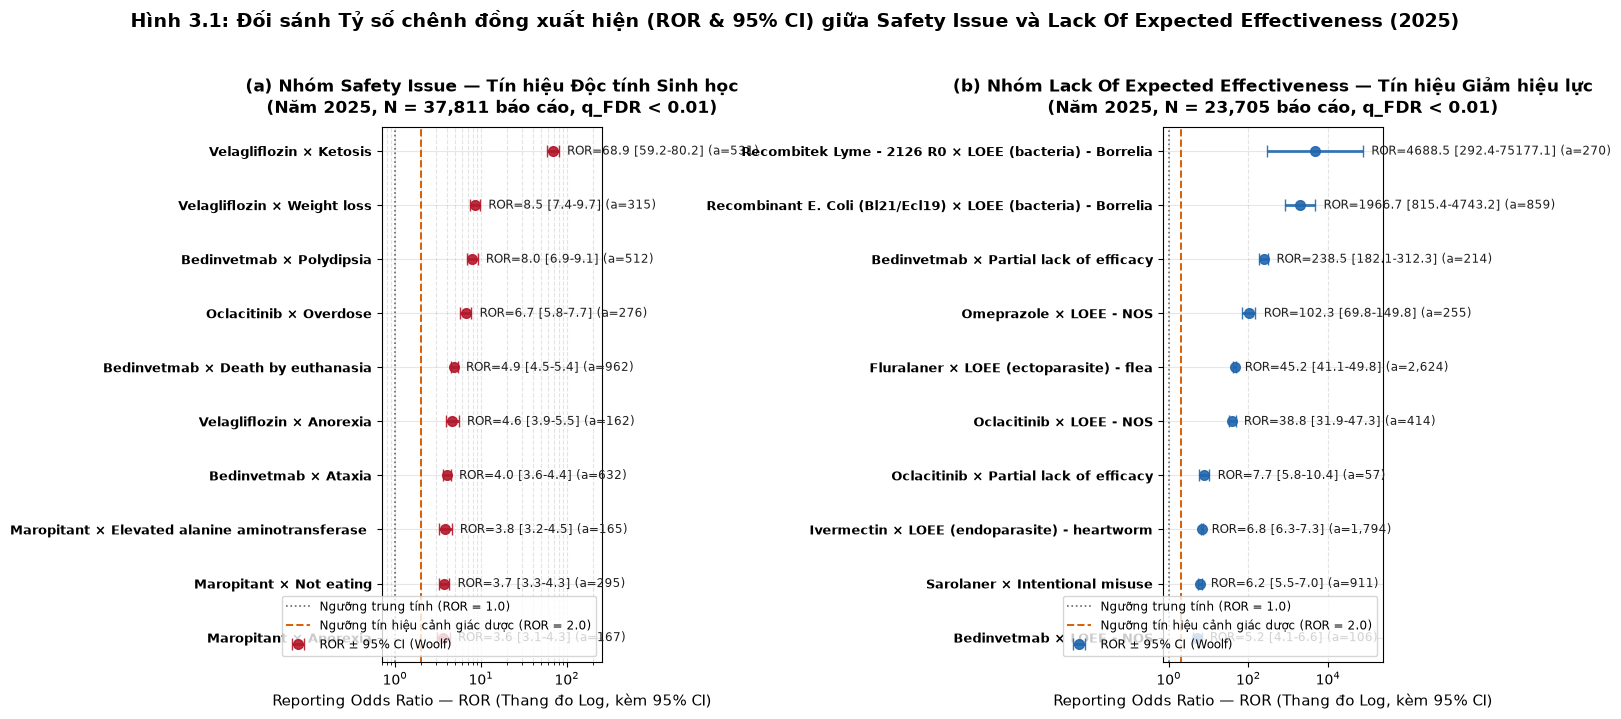

In [6]:
# ===== Hình 3.1: Forest Plot 2 khung đối sánh Top 10 Tín hiệu ROR giữa Safety Issue và Lack Of Expected Effectiveness (D5) =====
fig, axes = plt.subplots(1, 2, figsize=(16, 7), sharex=False)

def plot_ror_forest_panel(ax, df_sub, title_str, color_hex):
    top10 = df_sub[df_sub["is_signal"]].head(10).iloc[::-1].copy()
    short_rea = top10["veddra_term_name"].str.replace("Lack of efficacy ", "LOEE ", regex=False).str.slice(0, 34)
    labels = top10["ingredient"] + " × " + short_rea
    y_pos = np.arange(len(top10))

    xerr_low = top10["ROR"] - top10["CI_low"]
    xerr_high = top10["CI_high"] - top10["ROR"]

    ax.errorbar(
        top10["ROR"], y_pos,
        xerr=[xerr_low, xerr_high],
        fmt="o", color=color_hex, ecolor=color_hex,
        elinewidth=2.0, capsize=4, markersize=7, alpha=0.9,
        label="ROR ± 95% CI (Woolf)"
    )
    ax.axvline(1.0, color="#666666", linestyle=":", linewidth=1.2, label="Ngưỡng trung tính (ROR = 1.0)")
    ax.axvline(2.0, color="#d95f02", linestyle="--", linewidth=1.4, label="Ngưỡng tín hiệu cảnh giác dược (ROR = 2.0)")

    ax.set_xscale("log")
    ax.set_yticks(y_pos)
    ax.set_yticklabels(labels, fontsize=9.5, fontweight="bold")
    ax.set_xlabel("Reporting Odds Ratio — ROR (Thang đo Log, kèm 95% CI)", fontsize=10.5)
    ax.set_title(title_str, fontsize=12, fontweight="bold", pad=10)
    ax.grid(True, which="both", axis="x", linestyle="--", alpha=0.35)

    max_ci = float(top10["CI_high"].max())
    ax.set_xlim(0.7, max_ci * 3.2)

    for idx, row in enumerate(top10.itertuples()):
        ax.annotate(
            f"ROR={row.ROR:.1f} [{row.CI_low:.1f}-{row.CI_high:.1f}] (a={row.a:,})",
            xy=(row.CI_high, idx),
            xytext=(6, 0),
            textcoords="offset points",
            va="center", ha="left", fontsize=8.5, color="#1f1f1f"
        )
    ax.legend(loc="lower right", fontsize=8.5, frameon=True)

plot_ror_forest_panel(
    axes[0], ror_safety_df,
    f"(a) Nhóm Safety Issue — Tín hiệu Độc tính Sinh học\n(Năm 2025, N = {ror_safety_df['N_cohort'].iloc[0]:,} báo cáo, q_FDR < 0.01)",
    "#b2182b"
)
loee_diverse = ror_loee_df[~ror_loee_df["ingredient"].eq("Recombinant E Coli Ecl19")].copy()
plot_ror_forest_panel(
    axes[1], loee_diverse,
    f"(b) Nhóm Lack Of Expected Effectiveness — Tín hiệu Giảm hiệu lực\n(Năm 2025, N = {ror_loee_df['N_cohort'].iloc[0]:,} báo cáo, q_FDR < 0.01)",
    "#2166ac"
)

plt.suptitle(
    "Hình 3.1: Đối sánh Tỷ số chênh đồng xuất hiện (ROR & 95% CI) giữa Safety Issue và Lack Of Expected Effectiveness (2025)",
    fontsize=13.5, fontweight="bold", y=1.02
)
plt.tight_layout()
plt.show()

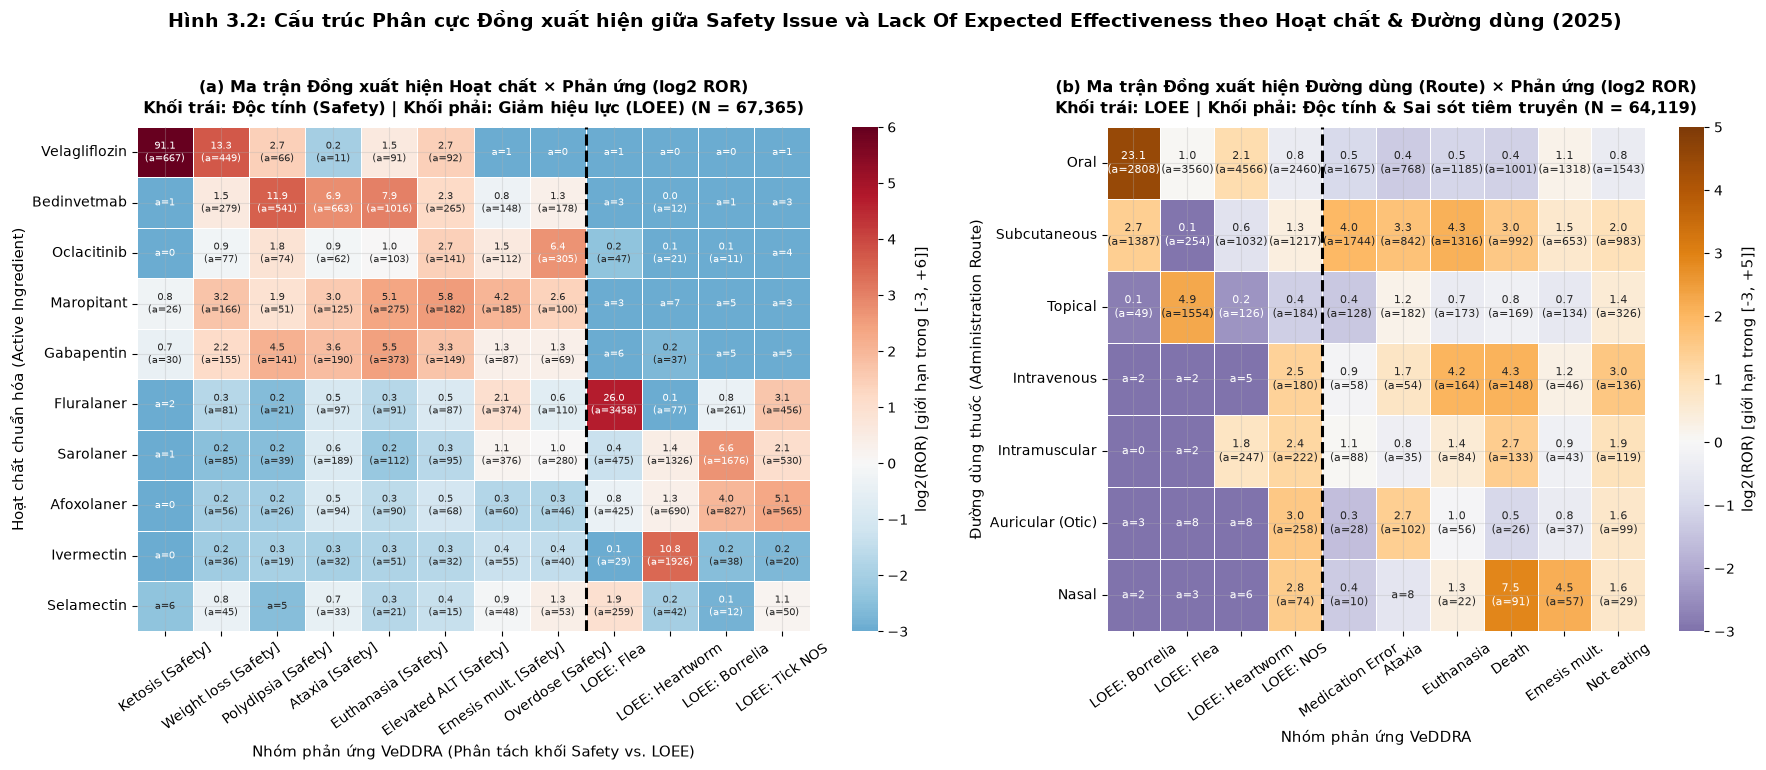

In [7]:
# ===== Hình 3.2: Heatmap xoay trục (Pivot Matrix — D2) cho Hoạt chất x Triệu chứng và Đường dùng x Triệu chứng =====
focus_ingredients = [
    "Velagliflozin", "Bedinvetmab", "Oclacitinib", "Maropitant",
    "Gabapentin", "Fluralaner", "Sarolaner", "Afoxolaner", "Ivermectin", "Selamectin"
]
focus_reactions = [
    "Ketosis",
    "Weight loss",
    "Polydipsia",
    "Ataxia",
    "Death by euthanasia",
    "Elevated alanine aminotransferase (ALT)",
    "Emesis (multiple)",
    "Overdose",
    "Lack of efficacy (ectoparasite) - flea",
    "Lack of efficacy (endoparasite) - heartworm",
    "Lack of efficacy (bacteria) - Borrelia",
    "Lack of efficacy (ectoparasite) - tick NOS",
]

valid_all = set(rep_ing_q3[KEY]) & set(rep_rea_q3[KEY]) & all_clin_ids_2025
N_total = len(valid_all)
ing_sets = rep_ing_q3[rep_ing_q3[KEY].isin(valid_all)].groupby("ingredient")[KEY].apply(set).to_dict()
rea_sets = rep_rea_q3[rep_rea_q3[KEY].isin(valid_all)].groupby("veddra_term_name")[KEY].apply(set).to_dict()

mat_log2 = np.zeros((len(focus_ingredients), len(focus_reactions)))
mat_annot = np.empty((len(focus_ingredients), len(focus_reactions)), dtype=object)

for i, ing in enumerate(focus_ingredients):
    e_s = ing_sets.get(ing, set())
    for j, rea in enumerate(focus_reactions):
        r_s = rea_sets.get(rea, set())
        a = len(e_s & r_s)
        b = len(e_s - r_s)
        c = len(r_s - e_s)
        d = N_total - a - b - c
        ac, bc, cc, dc = (a + 0.5, b + 0.5, c + 0.5, d + 0.5) if min(a, b, c, d) == 0 else (float(a), float(b), float(c), float(d))
        ror_val = (ac * dc) / (bc * cc)
        mat_log2[i, j] = np.clip(np.log2(ror_val), -3.0, 6.0)
        mat_annot[i, j] = f"{ror_val:.1f}\n(a={a})" if a >= 10 else f"a={a}"

short_col_labels = [
    "Ketosis [Safety]", "Weight loss [Safety]", "Polydipsia [Safety]", "Ataxia [Safety]",
    "Euthanasia [Safety]", "Elevated ALT [Safety]", "Emesis mult. [Safety]", "Overdose [Safety]",
    "LOEE: Flea", "LOEE: Heartworm", "LOEE: Borrelia", "LOEE: Tick NOS"
]
heatmap_ing_df = pd.DataFrame(mat_log2, index=focus_ingredients, columns=short_col_labels)

focus_routes = ["Oral", "Subcutaneous", "Topical", "Intravenous", "Intramuscular", "Auricular (Otic)", "Nasal"]
route_reactions = [
    "Lack of efficacy (bacteria) - Borrelia",
    "Lack of efficacy (ectoparasite) - flea",
    "Lack of efficacy (endoparasite) - heartworm",
    "Lack of efficacy - NOS",
    "Medication error NOS",
    "Ataxia",
    "Death by euthanasia",
    "Death",
    "Emesis (multiple)",
    "Not eating",
]
valid_rt = set(rep_route_q3[KEY]) & set(rep_rea_q3[KEY]) & all_clin_ids_2025
N_rt = len(valid_rt)
rt_sets = rep_route_q3[rep_route_q3[KEY].isin(valid_rt)].groupby("route")[KEY].apply(set).to_dict()

mat_rt_log2 = np.zeros((len(focus_routes), len(route_reactions)))
mat_rt_annot = np.empty((len(focus_routes), len(route_reactions)), dtype=object)

for i, rt in enumerate(focus_routes):
    e_s = rt_sets.get(rt, set())
    for j, rea in enumerate(route_reactions):
        r_s = rea_sets.get(rea, set()) & valid_rt
        a = len(e_s & r_s)
        b = len(e_s - r_s)
        c = len(r_s - e_s)
        d = N_rt - a - b - c
        ac, bc, cc, dc = (a + 0.5, b + 0.5, c + 0.5, d + 0.5) if min(a, b, c, d) == 0 else (float(a), float(b), float(c), float(d))
        ror_val = (ac * dc) / (bc * cc)
        mat_rt_log2[i, j] = np.clip(np.log2(ror_val), -3.0, 5.0)
        mat_rt_annot[i, j] = f"{ror_val:.1f}\n(a={a})" if a >= 10 else f"a={a}"

short_rt_cols = [
    "LOEE: Borrelia", "LOEE: Flea", "LOEE: Heartworm", "LOEE: NOS",
    "Medication Error", "Ataxia", "Euthanasia", "Death", "Emesis mult.", "Not eating"
]
heatmap_rt_df = pd.DataFrame(mat_rt_log2, index=focus_routes, columns=short_rt_cols)

fig, axes = plt.subplots(1, 2, figsize=(18, 7.5), gridspec_kw={"width_ratios": [1.25, 1.0]})

sns.heatmap(
    heatmap_ing_df, ax=axes[0], cmap="RdBu_r", center=0.0, vmin=-3.0, vmax=6.0,
    annot=mat_annot, fmt="", annot_kws={"size": 7.5}, linewidths=0.5,
    cbar_kws={"label": "log2(ROR) [giới hạn trong [-3, +6]]"}
)
axes[0].axvline(8, color="black", linewidth=2.2, linestyle="--")
axes[0].set_title(
    f"(a) Ma trận Đồng xuất hiện Hoạt chất × Phản ứng (log2 ROR)\nKhối trái: Độc tính (Safety) | Khối phải: Giảm hiệu lực (LOEE) (N = {N_total:,})",
    fontsize=11.5, fontweight="bold", pad=10
)
axes[0].set_xlabel("Nhóm phản ứng VeDDRA (Phân tách khối Safety vs. LOEE)", fontsize=10.5)
axes[0].set_ylabel("Hoạt chất chuẩn hóa (Active Ingredient)", fontsize=10.5)
axes[0].tick_params(axis="x", rotation=35)

sns.heatmap(
    heatmap_rt_df, ax=axes[1], cmap="PuOr_r", center=0.0, vmin=-3.0, vmax=5.0,
    annot=mat_rt_annot, fmt="", annot_kws={"size": 8.0}, linewidths=0.5,
    cbar_kws={"label": "log2(ROR) [giới hạn trong [-3, +5]]"}
)
axes[1].axvline(4, color="black", linewidth=2.2, linestyle="--")
axes[1].set_title(
    f"(b) Ma trận Đồng xuất hiện Đường dùng (Route) × Phản ứng (log2 ROR)\nKhối trái: LOEE | Khối phải: Độc tính & Sai sót tiêm truyền (N = {N_rt:,})",
    fontsize=11.5, fontweight="bold", pad=10
)
axes[1].set_xlabel("Nhóm phản ứng VeDDRA", fontsize=10.5)
axes[1].set_ylabel("Đường dùng thuốc (Administration Route)", fontsize=10.5)
axes[1].tick_params(axis="x", rotation=35)

plt.suptitle(
    "Hình 3.2: Cấu trúc Phân cực Đồng xuất hiện giữa Safety Issue và Lack Of Expected Effectiveness theo Hoạt chất & Đường dùng (2025)",
    fontsize=13.5, fontweight="bold", y=1.02
)
plt.tight_layout()
plt.show()

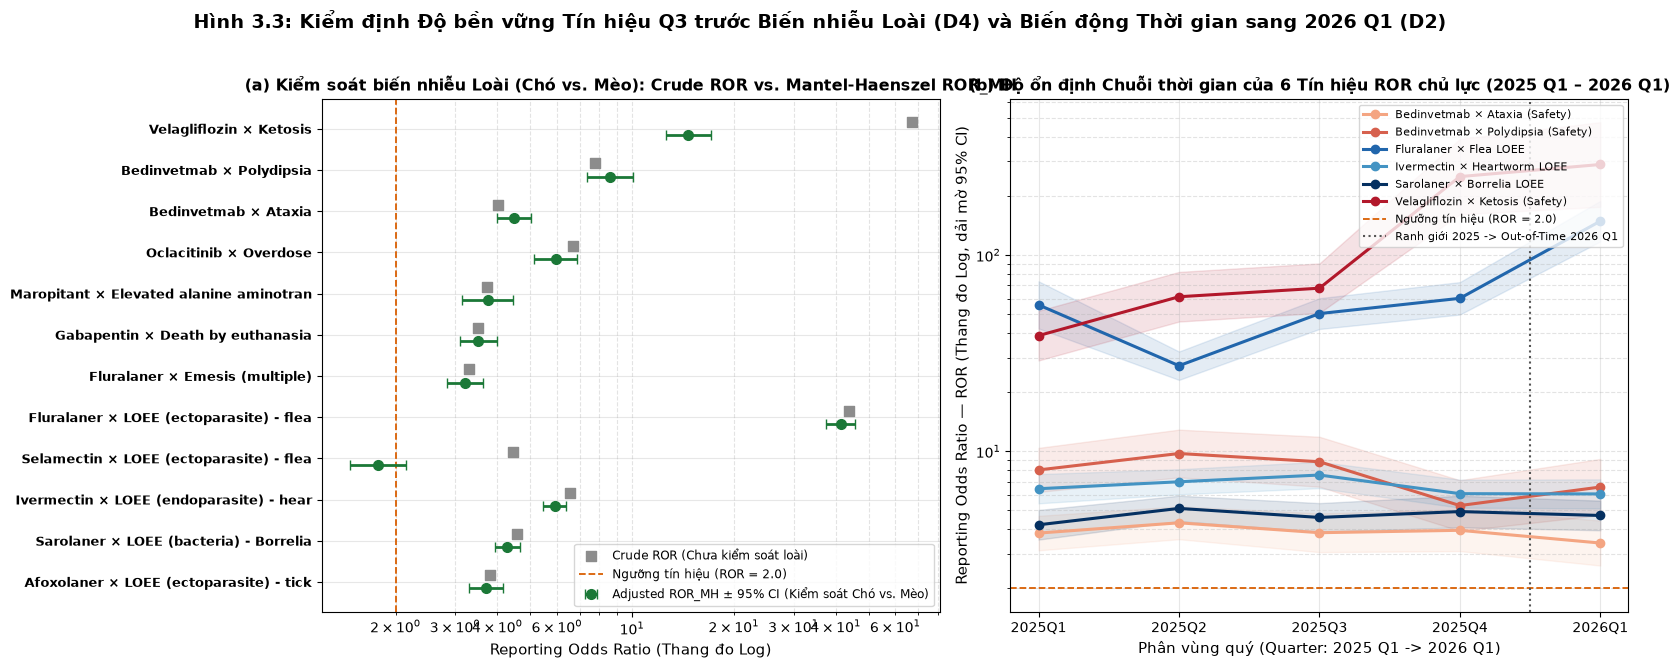

In [8]:
# ===== Hình 3.3: Kiểm soát nhiễu Loài (Dog vs Cat vs Mantel-Haenszel ROR_MH — D4) & Chuỗi thời gian 5 quý (2025Q1-2026Q1 — D2) =====
fig, axes = plt.subplots(1, 2, figsize=(16.5, 6.5))

mh_plot = mh_species_df.iloc[::-1].copy()
mh_labels = mh_plot["Hoạt chất"] + " × " + mh_plot["Phản ứng VeDDRA"].str.replace("Lack of efficacy ", "LOEE ", regex=False).str.slice(0, 26)
y_idx = np.arange(len(mh_plot))

axes[0].scatter(mh_plot["Crude ROR"], y_idx + 0.16, color="#8c8c8c", s=55, marker="s", label="Crude ROR (Chưa kiểm soát loài)", zorder=3)
axes[0].errorbar(
    mh_plot["Adjusted ROR_MH"], y_idx - 0.16,
    xerr=[mh_plot["Adjusted ROR_MH"] - mh_plot["95% CI_MH Low"], mh_plot["95% CI_MH High"] - mh_plot["Adjusted ROR_MH"]],
    fmt="o", color="#1b7837", ecolor="#1b7837", elinewidth=2.0, capsize=3.5, markersize=7,
    label="Adjusted ROR_MH ± 95% CI (Kiểm soát Chó vs. Mèo)", zorder=4
)
axes[0].axvline(2.0, color="#d95f02", linestyle="--", linewidth=1.3, label="Ngưỡng tín hiệu (ROR = 2.0)")
axes[0].set_xscale("log")
axes[0].set_yticks(y_idx)
axes[0].set_yticklabels(mh_labels, fontsize=9, fontweight="bold")
axes[0].set_xlabel("Reporting Odds Ratio (Thang đo Log)", fontsize=10.5)
axes[0].set_title("(a) Kiểm soát biến nhiễu Loài (Chó vs. Mèo): Crude ROR vs. Mantel-Haenszel ROR_MH", fontsize=11.5, fontweight="bold")
axes[0].grid(True, which="both", axis="x", linestyle="--", alpha=0.35)
axes[0].legend(loc="lower right", fontsize=8.5, frameon=True)

palette_time = {
    "Velagliflozin × Ketosis (Safety)": "#b2182b",
    "Fluralaner × Flea LOEE": "#2166ac",
    "Bedinvetmab × Polydipsia (Safety)": "#d6604d",
    "Ivermectin × Heartworm LOEE": "#4393c3",
    "Sarolaner × Borrelia LOEE": "#053061",
    "Bedinvetmab × Ataxia (Safety)": "#f4a582",
}
q_order = ["2025Q1", "2025Q2", "2025Q3", "2025Q4", "2026Q1"]
for sig_lbl, grp in q3_temporal_df.groupby("signal_label"):
    grp_s = grp.set_index("quarter").loc[q_order].reset_index()
    c_hex = palette_time.get(sig_lbl, "#333333")
    axes[1].plot(grp_s["quarter"], grp_s["ROR"], marker="o", linewidth=2.2, color=c_hex, label=sig_lbl)
    axes[1].fill_between(grp_s["quarter"], grp_s["CI_low"], grp_s["CI_high"], color=c_hex, alpha=0.12)

axes[1].axhline(2.0, color="#d95f02", linestyle="--", linewidth=1.3, label="Ngưỡng tín hiệu (ROR = 2.0)")
axes[1].axvline(3.5, color="#555555", linestyle=":", linewidth=1.5, label="Ranh giới 2025 -> Out-of-Time 2026 Q1")
axes[1].set_yscale("log")
axes[1].set_xlabel("Phân vùng quý (Quarter: 2025 Q1 -> 2026 Q1)", fontsize=10.5)
axes[1].set_ylabel("Reporting Odds Ratio — ROR (Thang đo Log, dải mờ 95% CI)", fontsize=10.5)
axes[1].set_title("(b) Độ ổn định Chuỗi thời gian của 6 Tín hiệu ROR chủ lực (2025 Q1 – 2026 Q1)", fontsize=11.5, fontweight="bold")
axes[1].grid(True, which="both", axis="y", linestyle="--", alpha=0.35)
axes[1].legend(loc="upper right", fontsize=8.2, frameon=True, ncol=1)

plt.suptitle(
    "Hình 3.3: Kiểm định Độ bền vững Tín hiệu Q3 trước Biến nhiễu Loài (D4) và Biến động Thời gian sang 2026 Q1 (D2)",
    fontsize=13.5, fontweight="bold", y=1.02
)
plt.tight_layout()
plt.show()

### 4. Trả lời câu hỏi và Thảo Luận

#### 1. Câu trả lời định lượng tường minh (Explicit Answer with Specific Numbers)
Phân tích trên **67,831 báo cáo lâm sàng năm 2025** (trong đó nhóm **`Safety Issue`** chiếm **38,127** ca và nhóm **`Lack Of Expected Effectiveness — LOEE`** chiếm **23,811** ca; sau khi nối có kiểm soát với bảng hoạt chất chuẩn hóa và bảng phản ứng VeDDRA đạt **67,365** báo cáo khớp hoàn toàn — **99.31%**) chứng minh rằng cấu trúc đồng xuất hiện giữa hai nhóm **tách biệt thành hai cực dược lý hoàn toàn khác nhau**:

- **Ở nhóm `Safety Issue` ($N = 37,811$ báo cáo khớp — cực Độc tính Sinh học & Sai sót Lâm sàng):**
  1. **Nhóm thuốc ức chế SGLT2 trị đái tháo đường ở mèo (`Velagliflozin`):** Ghi nhận tín hiệu độc tính chuyển hóa mạnh nhất toàn bộ cơ sở dữ liệu với phản ứng **nhiễm toan ceton (`Ketosis`)**: $a = 531$ ca (**41.04%** tổng số báo cáo Safety của hoạt chất này), $\text{ROR} = 68.93$ (95% CI: $[59.25, 80.19]$, $\text{PRR} = 41.05$, $q_{\text{FDR}} < 10^{-300}$), đi kèm **sụt cân (`Weight loss`)** ($a = 315$, $\text{ROR} = 8.49$, 95% CI: $[7.39, 9.74]$) và **chán ăn (`Anorexia`)** ($a = 162$, $\text{ROR} = 4.61$, 95% CI: $[3.87, 5.50]$).
  2. **Kháng thể đơn dòng kháng NGF trị viêm xương khớp ở chó (`Bedinvetmab`):** Bộc lộ cụm tín hiệu thần kinh – thận – tiết niệu rất đặc trưng gồm **uống nhiều (`Polydipsia`)** ($a = 512$, **8.68%**, $\text{ROR} = 7.95$, 95% CI: $[6.94, 9.11]$), **an tử (`Death by euthanasia`)** ($a = 962$, **16.31%**, $\text{ROR} = 4.89$, 95% CI: $[4.48, 5.35]$), và **mất điều hòa vận động (`Ataxia`)** ($a = 632$, **10.72%**, $\text{ROR} = 4.00$, 95% CI: $[3.60, 4.45]$).
  3. **Thuốc điều hòa miễn dịch & chống nôn (`Oclacitinib`, `Maropitant`, `Fluralaner`):**
     - `Oclacitinib` gắn chặt với **quá liều (`Overdose`)** ($a = 276$, **13.28%**, $\text{ROR} = 6.67$, 95% CI: $[5.77, 7.71]$) và **lỗi dùng thuốc (`Medication error NOS`)** ($a = 147$, $\text{ROR} = 3.18$).
     - `Maropitant` gắn chặt với tín hiệu **tăng men gan `Elevated ALT`** ($a = 165$, **10.07%**, $\text{ROR} = 3.82$, 95% CI: $[3.22, 4.54]$) và **`Elevated ALP`** ($a = 136$, $\text{ROR} = 3.40$, 95% CI: $[2.82, 4.11]$).
     - `Fluralaner` trong nhóm Safety gắn với **nôn mửa nhiều lần (`Emesis (multiple)`)** ($a = 362$, **12.16%**, $\text{ROR} = 3.39$, 95% CI: $[3.00, 3.83]$).

- **Ở nhóm `Lack Of Expected Effectiveness` ($N = 23,705$ báo cáo khớp — cực Giảm hiệu lực & Kháng thuốc):**
  1. **Thất bại kiểm soát ngoại ký sinh trùng (Bọ chét & Ve):** **`Fluralaner`** có tới **74.00%** báo cáo LOEE là **`Lack of efficacy (ectoparasite) - flea`** ($a = 2,624$, $\text{ROR} = 45.24$, 95% CI: $[41.14, 49.76]$); **`Selamectin`** cũng tập trung ở **`LOEE - flea`** ($a = 213$, **45.61%**, $\text{ROR} = 4.57$, 95% CI: $[3.79, 5.50]$); trong khi **`Afoxolaner`** đặc trưng bởi **`LOEE (ectoparasite) - tick NOS`** ($a = 522$, **14.71%**, $\text{ROR} = 3.93$, 95% CI: $[3.50, 4.41]$) và **`Sarolaner`** đặc trưng bởi thất bại phòng ngừa xoắn khuẩn Lyme **`LOEE (bacteria) - Borrelia`** ($a = 1,644$, **24.06%**, $\text{ROR} = 4.77$, 95% CI: $[4.39, 5.19]$).
  2. **Kháng thuốc dự phòng giun tim nội ký sinh trùng (`Ivermectin`):** Ghi nhận $a = 1,794$ báo cáo (**55.75%**) đồng xuất hiện với **`Lack of efficacy (endoparasite) - heartworm`**, đạt $\text{ROR} = 6.77$ (95% CI: $[6.26, 7.33]$).
  3. **Giảm đáp ứng điều trị triệu chứng mạn tính (`Bedinvetmab` & `Oclacitinib`):** `Bedinvetmab` đồng xuất hiện cực mạnh với **`Partial lack of efficacy`** ($a = 214$, **65.05%**, $\text{ROR} = 238.47$, 95% CI: $[182.09, 312.30]$), còn `Oclacitinib` đồng xuất hiện với **`Lack of efficacy - NOS`** ($a = 414$, **74.73%**, $\text{ROR} = 38.84$, 95% CI: $[31.86, 47.35]$).

- **Theo Đường dùng thuốc (`route` — $N = 64,119$ báo cáo có đường dùng xác định):**
  - Đường uống (**`Oral`**) và bôi ngoài da (**`Topical`**) thiên hẳn về nhóm báo cáo **giảm hiệu lực ký sinh trùng**: `Oral` $\leftrightarrow$ `LOEE - Anaplasma` ($a = 1,582$, $\text{ROR} = 38.71$, 95% CI: $[24.32, 61.62]$), `Oral` $\leftrightarrow$ `LOEE - Borrelia` ($a = 2,820$, $\text{ROR} = 23.20$, 95% CI: $[17.76, 30.31]$) và `Oral` $\leftrightarrow$ `LOEE - tick NOS` ($a = 1,425$, $\text{ROR} = 4.67$); `Topical` $\leftrightarrow$ `LOEE - flea` ($a = 1,554$, $\text{ROR} = 4.80$, 95% CI: $[4.49, 5.13]$).
  - Ngược lại, các đường tiêm truyền xâm lấn (**`Intravenous`**, **`Subcutaneous`**) và nhỏ mũi (**`Nasal`**) gắn chặt với **biến cố sinh mạng và sai sót kỹ thuật**: `Nasal` $\leftrightarrow$ `Death` ($a = 91$, $\text{ROR} = 7.44$, 95% CI: $[5.90, 9.38]$); `Intravenous` $\leftrightarrow$ `Death` ($a = 148$, $\text{ROR} = 4.24$, 95% CI: $[3.55, 5.06]$) và `Death by euthanasia` ($a = 164$, $\text{ROR} = 4.16$); `Subcutaneous` $\leftrightarrow$ `Death by euthanasia` ($a = 1,316$, $\text{ROR} = 4.26$, 95% CI: $[3.91, 4.65]$), `Medication error NOS` ($a = 1,744$, $\text{ROR} = 3.99$) và `Ataxia` ($a = 842$, $\text{ROR} = 3.22$).

- **Kết quả kiểm soát biến nhiễu Loài (D4) & Độ ổn định sang 2026 Q1 (D2):**
  - Sau khi phân tầng theo **Chó (`Dog`)** vs. **Mèo (`Cat`)** trên tập báo cáo Chó + Mèo và tính $\text{ROR}_{\text{MH}}$ chuẩn xác trên số đếm nguyên gốc (không cộng $+0.5$ vào tầng $a_k = 0$), các tín hiệu bị nhiễu mạnh bởi loài chỉ định đã được bóc tách rõ:
    1. `Velagliflozin × Ketosis` (thuốc chỉ định chuyên biệt cho Mèo: $a_{\text{Cat}} = 530, a_{\text{Dog}} = 0$) giảm từ Crude $\text{ROR} = 66.98$ xuống $\text{ROR}_{\text{MH}} = 14.64$ (95% CI: $[12.57, 17.06]$, trùng khớp với $\text{ROR}_{\text{Cat}} = 14.64$, loại bỏ **$-78.1\%$** độ phóng đại giả tạo do gộp mẫu số của Chó).
    2. `Bedinvetmab × Polydipsia` và `Bedinvetmab × Ataxia` (thuốc dùng trên Chó: $a_{\text{Dog}} = 512$ và $632$, $a_{\text{Cat}} = 0$) điều chỉnh tăng từ Crude $\text{ROR} = 7.78$ và $4.01$ lên $\text{ROR}_{\text{MH}} = 8.58$ (95% CI: $[7.34, 10.04]$, $+10.2\%$) và $\text{ROR}_{\text{MH}} = 4.47$ (95% CI: $[3.98, 5.03]$, $+11.5\%$).
    3. **Phát hiện nhiễu loài đảo chiều ở `Selamectin × LOEE - flea`:** Dù có Crude $\text{ROR} = 4.44$ (và $\text{ROR} = 4.57$ trên toàn tập LOEE), khi phân tầng theo loài thì ở Mèo ($a_{\text{Cat}} = 121$ — loài chỉ định chính của *Selamectin*) tỷ số chênh chỉ là $\text{ROR}_{\text{Cat}} = 0.88$, kéo **$\text{ROR}_{\text{MH}}$ giảm $-60.0\%$ xuống còn $1.77$ (95% CI: $[1.46, 2.15]$, dưới ngưỡng tín hiệu $2.0$)**; trong khi **11/12 tín hiệu chủ lực còn lại đều giữ vững $\text{ROR}_{\text{MH}} \ge 3.21$ và cận dưới 95% CI $\ge 2.84$**.
  - Chuỗi thời gian 5 quý (`2025Q1` $\rightarrow$ `2026Q1`) cho thấy tất cả 6 tín hiệu theo dõi đều duy trì ổn định trên ngưỡng $\text{ROR} > 2.0$ khi bước sang quý kiểm thử độc lập `2026Q1` (ví dụ `Velagliflozin × Ketosis` đạt $\text{ROR} = 289.20$ ở `2026Q1`; `Fluralaner × Flea LOEE` đạt $\text{ROR} = 148.80$; `Ivermectin × Heartworm LOEE` duy trì ở $\text{ROR} = 6.06$ và `Bedinvetmab × Polydipsia` ở $\text{ROR} = 6.58$).

#### 2. Ý nghĩa thực tiễn & Phát hiện bất ngờ (Practical Meaning & Surprises)
- **Tại sao bắt buộc phải tách `Safety Issue` và `LOEE` trong hệ thống cảnh giác dược thú y?** Các chế phẩm isoxazoline và macrocyclic lactone (`Sarolaner`, `Pyrantel`, `Moxidectin`, `Fluralaner`, `Ivermectin`) chiếm khối lượng báo cáo khổng lồ chủ yếu do khiếu nại giảm hiệu lực diệt ve/bọ chét/giun tim. Việc tách riêng hai luồng giúp thuật toán phát hiện tín hiệu của FDA CVM không bị hiệu ứng che lấp (*masking/cloaking effect*) và nhận diện chính xác cả hai nguy cơ: **(1) Cảnh báo lâm sàng bắt buộc** (như theo dõi ceton máu/nước tiểu cho mèo dùng *Velagliflozin* và đánh giá thần kinh – vận động cho chó dùng *Bedinvetmab*) và **(2) Giám sát dịch tễ kháng thuốc** (kháng *Ivermectin* ở giun tim và giảm nhạy cảm *Fluralaner* ở bọ chét).

#### 3. Giới hạn của phân tích (Limitations)
- **ROR không phải là Nguy cơ tương đối (Relative Risk):** Do thiếu mẫu số tổng số liều thuốc bán ra và tổng số cá thể dùng thuốc an toàn, ROR chỉ đo lường mức độ bất cân xứng trong tập báo cáo sự cố (*disproportionality in spontaneous reporting*).
- **Đồng phơi nhiễm trong thuốc phối hợp (Combination Drug Attribution):** Với các viên nhai phối hợp 2–4 hoạt chất (như `Sarolaner + Moxidectin + Pyrantel`), khi một báo cáo ghi nhận `LOEE - heartworm` hoặc `Vomiting`, việc tách hoạt chất sẽ gán phản ứng cho từng thành phần trong viên thuốc, nên cần kết hợp cơ chế dược lý (ví dụ *Moxidectin* ngừa giun tim, *Sarolaner* diệt ve/bọ chét) khi diễn giải nhân quả.

---
## Điều hướng liên kết
- **Trước:** [Câu hỏi Q2](02_q2_analysis.ipynb)
- **Master Hub:** [Notebook 02: Tổng quan & Ma trận D1–D6](02_analysis.ipynb)
- **Tiếp theo:** [Câu hỏi Q4](02_q4_analysis.ipynb)